## Definició de paràmetres

In [32]:
import numpy as np
import matplotlib.pyplot as plt

#DEFINICIÓ DE LES CONSTANTS

#Propietats del teixit
C_v = 3698        #[J/(kg K)]   Calor específic
Rho = 1081        #[kg/m^3]     Densitat
k = 0.56          #[W/(m K)]    Conductivitat tèrmica
Sigma = 0.472     #[S/m ]       Conductivitat elèctrica

#Condicions del problema
V = 40/np.sqrt(2) #[V]    Voltatge eficaç
T_c = 36.5        #[ºC]   Temperatura corporal
d = 0.02          #[m]    Gruix teixit
d_malalt = 0.005  #[m]    Gruix teixit malalt

#Constants de normalització i càlculs posteriors

alpha = k / (C_v * Rho)       #[m^2/s]  Difusivitat tèrmica
t_0 = d**2 / alpha            #[s]      Temps característic
T_0 = (Sigma * V**2) / k      #[ºC]     Temperatura característica
Tc_norm = T_c / T_0           #adim     Temperatura normalitzada

theta_50 = 50 / T_0      # adimensional
theta_80 = 80 / T_0      # adimensional


#DISCRETITZACIÓ (Dades del guió)

N = 101
t_a = 0.025              # adimensional
factors_dt = (0.5, 1)    # Delta t = factors_dt * (Delta x)^2

#FUNCIONS DE NORMALITZACIÓ

def normalitza_temperatura(T):
    return T / T_0

def desnormalitza_temperatura(T):
    return T * T_0

def desnormalitza_temps(t):
    return t * t_0

## Solució analítica

In [33]:
#SOLUCIÓ ANALÍTICA

def T_analitica(x, t, Tc_norm, n_termes=200):     # Definim una funció per les temperatures normalitzades

    T_an = np.full(len(x), Tc_norm, dtype=float)     # Temperatura inicial constant Tcn

    # Fem un sumatori (al codi ha de tenir límit) per representar la sèrie de Fourier que defineix la temperatura

    for n in range(1, 2*n_termes, 2):         # n senars (salts de 2)
        a  = (n * np.pi)**2                   # an trobat per Fourier
        bn = 4 / (n * np.pi)                  # bn trobat per Fourier
        T_an += bn * (1 - np.exp(-a * t)) / a * np.sin(n * np.pi * x)   # Anem sumant cada valor posterior fins arribar a l'n que volguem
    return T_an

# Comparem el valor al centre amb n diferents
for nmax in [5, 21, 101, 999]:
    print(nmax,"->", T_analitica(np.array([0.5]), t_a, Tc_norm, nmax)[0])
print()
print("Com veiem que a partir de 100 no canvia quasi res, podem utilitzar-lo com a substitut de la suma infinita")

5 -> 0.07891068530658282
21 -> 0.07885051929711749
101 -> 0.07884965943457076
999 -> 0.07884965161805291

Com veiem que a partir de 100 no canvia quasi res, podem utilitzar-lo com a substitut de la suma infinita


In [34]:
#COMPROVACIÓ, VERIFIQUEM QUE SIGUI LA SOLUCIÓ

x = np.linspace(0, 1, N)     # Creem un vector amb 101 punts equiespaiats entre 0 i 1

# Comprovem les condicions inicials (Tn = Tcn en t=0 i x=0, x=1)
print("Condicions inicials (t=0):", np.max(np.abs(T_analitica(x, 0, Tc_norm) - Tc_norm)))
print("Condicions de contorn (x=0, x=1):", T_analitica(np.array([0.0, 1.0]), t_a, Tc_norm) - Tc_norm)

# Comprovem que sigui solució
xp = np.array([0.3])     # Fixem un punt x interior
tp = 0.02                # Fixem un temps t interior
e = 1e-4                 # Prenem un increment petit
Tt = (T_analitica(xp, tp+e, Tc_norm) - T_analitica(xp, tp-e, Tc_norm)) / (2 * e)                                      # Derivada temporal centrada
Txx = (T_analitica(xp+e, tp, Tc_norm) - 2 * T_analitica(xp, tp, Tc_norm) + T_analitica(xp-e, tp, Tc_norm)) / e**2     # Segona derivada espaial centrada
print()
print("Tt - Txx =", (Tt - Txx)[0])              # Tt = Txx + 1 => Tt - Txx = 1
print("Si és aproximadament 1, és correcte.")
print()
print("Error del càlcul del règim estacionari:", np.max(np.abs(T_analitica(x, 10, Tc_norm) - (Tc_norm + x*(1-x)/2))))     # t=10 és molt gran comparat amb els temps utilitzats, el prenem com a infinit
print("Si és aproximadament 0, és correcte.")

Condicions inicials (t=0): 0.0
Condicions de contorn (x=0, x=1): [0. 0.]

Tt - Txx = 0.9980356099402454
Si és aproximadament 1, és correcte.

Error del càlcul del règim estacionari: 3.000185704038483e-08
Si és aproximadament 0, és correcte.


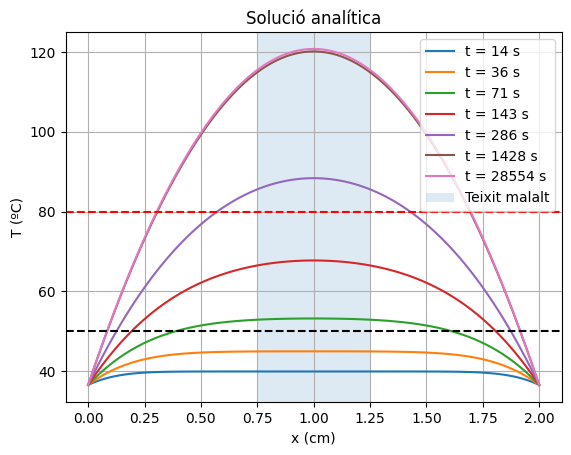


Veiem que a partir del tn = 0.5 no canvien els resultats i que el millor temps estarà entre ~70s i ~200s.


In [35]:
#REPRESENTACIÓ GRÀFICA SOLUCIÓ ANALÍTICA

x = np.linspace(0, 1, 101)

plt.figure()
for t in [0.005, 0.0125, 0.025, 0.05, 0.1, 0.5, 10]:                        # Provem diferents intervals de temps adimensional
    plt.plot(x*2, T_analitica(x, t, Tc_norm)*T_0, label=f"t = {t*t_0:.0f} s")   # Canviem de x adimensional a x (xn * d) de Tn a T (Tn*T0) i de tn a t (tn * t0)
plt.axvspan(0.75, 1.25, alpha=0.15, label="Teixit malalt")
plt.axhline(50, color="k", ls="--")     # Límit inferior per curar el teixit malalt
plt.axhline(80, color="r", ls="--")     # Límit superior per no fer mal al cor
plt.xlabel("x (cm)")
plt.ylabel("T (ºC)")
plt.title("Solució analítica")
plt.legend()
plt.grid()
plt.show()

print()
print("Veiem que a partir del tn = 0.5 no canvien els resultats i que el millor temps estarà entre ~70s i ~200s.")

## Mètode Euler Explícit

In [36]:
#EULER EXPLÍCIT

# Definim la funció d'Euler explícit

def euler_expl(N, gamma, t_a):
    x = np.linspace(0, 1, N)
    dx = x[1] - x[0]      # Un pas en x
    dt = gamma * dx**2    # Un pas en t
    p = round(t_a / dt)    # Arrodonim el nombre de passes en t ja que per a alguns valors t_adim/dt no és enter
    dt = t_a / p           # Trobem el nou pas en t ajustat (~ l'anterior)
    g = dt / dx**2        # Trobem la gamma ajustada (~ la anterior)

    T = np.full(N, Tc_norm)   # Condicions inicials
    for i in range(p):    # Avancem passes temporals
        T[1:-1] = g * (T[2:] - 2*T[1:-1] + T[:-2]) + dt + T[1:-1]   # Actualitzem el valor de T per a cada pas
    return x, T

#Execució Euler Explícit i càlcul de l'error (comparant amb la sol. analítica)

casos = [0.51, 0.49, 0.25]    # Amb gamma > 0.5 hauria de petar
sol = {}
err = {}

for g in casos:
    x, T = euler_expl(N, g, t_a)   # Recuperem els valors de la funció
    sol[g] = T                                             # Guarda el valor de T per a cada gamma
    err[g] = np.abs(T - T_analitica(x, t_a, Tc_norm))      # Guarda l'error de T respecte a la solució analítica per a cada gamma
    print(f"Gamma = {g} -> Error màxim = {err[g].max():.2e}  ({err[g].max()*T_0:.5} ºC)")
print()
print("Comprovem que efectivament, per a gamma > 0.5, el mètode peta i ens dona errors absurds.")
print()
print()

#Desnormalització

x, T = euler_expl(101, 0.25, t_a)
T = T*T_0
enfermo = (x >= 0.375) & (x <= 0.625)

print("t =", t_a*t_0, "s")
print("T màxima:", T.max(), "°C")
print("T mínima al teixit malalt:", T[enfermo].min(), "°C")
print("T màxima al teixit sa:", T[~enfermo].max(), "°C")

Gamma = 0.51 -> Error màxim = 2.07e+00  (1399.0 ºC)
Gamma = 0.49 -> Error màxim = 3.97e-06  (0.0026795 ºC)
Gamma = 0.25 -> Error màxim = 1.02e-06  (0.00069092 ºC)

Comprovem que efectivament, per a gamma > 0.5, el mètode peta i ens dona errors absurds.


t = 71.38460714285715 s
T màxima: 53.1676052518597 °C
T mínima al teixit malalt: 52.88682850792023 °C
T màxima al teixit sa: 52.83084807693183 °C


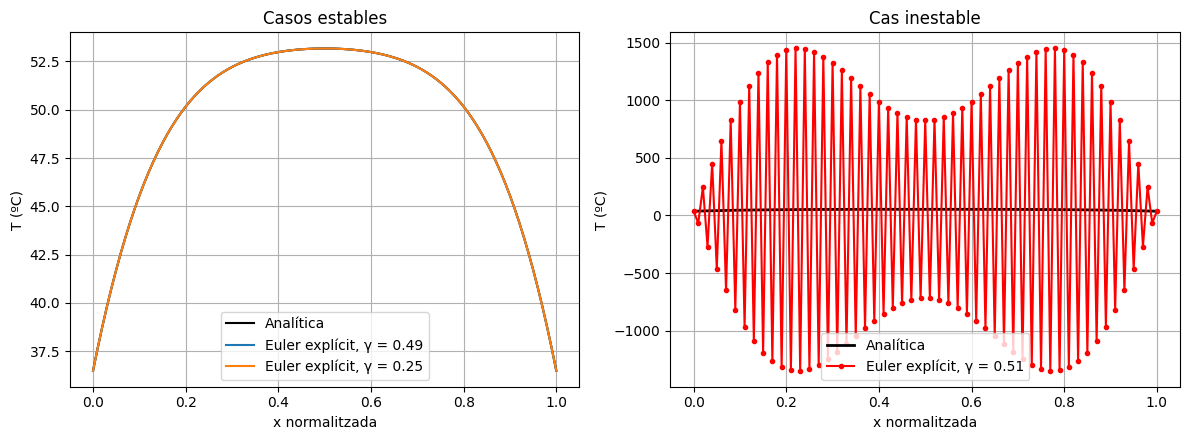


Es veu clarament que el mètode d'Euler amb gammes < 0.5 és una molt bona aproximació
i no s'aprecia diferència entre les dues gammes però per g>0.5 el resultat peta i no té res a veure.




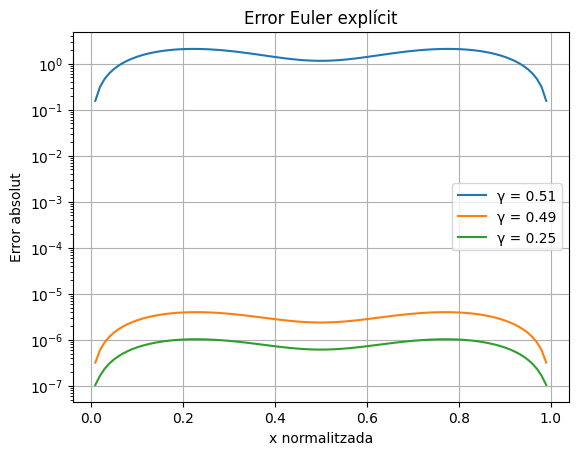

In [37]:
#REPRESENTACIÓ GRÀFICA EULER EXPLÍCIT

fig, ax = plt.subplots(1, 2, figsize=(12,4.5))      # Fem 2 plots per poder apreciar la diferència

ax[0].plot(x, T_analitica(x, t_a, Tc_norm)*T_0, "k", label="Analítica")             # Gràfica de temperatura analítica
ax[0].plot(x, sol[0.49]*T_0, "-", label="Euler explícit, γ = 0.49")                # Gràfica d'Euler per a gamma 0.49
ax[0].plot(x, sol[0.25]*T_0, "-", label="Euler explícit, γ = 0.25")                # Gràfica d'Euler per a gamma 0.25
ax[0].set_xlabel("x normalitzada")
ax[0].set_ylabel("T (ºC)")
ax[0].set_title("Casos estables")
ax[0].legend()
ax[0].grid()

ax[1].plot(x, T_analitica(x, t_a, Tc_norm)*T_0, "k", lw=2, label="Analítica")     # Gràfica de temperatura analítica
ax[1].plot(x, sol[0.51]*T_0, "r.-", label="Euler explícit, γ = 0.51")             # Gràfica per a l'Euler quan la gamma peta
ax[1].set_xlabel("x normalitzada")
ax[1].set_ylabel("T (ºC)")
ax[1].set_title("Cas inestable")
ax[1].legend()
ax[1].grid()

plt.tight_layout()
plt.show()

print()
print("Es veu clarament que el mètode d'Euler amb gammes < 0.5 és una molt bona aproximació")
print("i no s'aprecia diferència entre les dues gammes però per g>0.5 el resultat peta i no té res a veure.")
print()
print()

#Errors en escala logarítmica (treiem els extrems perquè allà l'error és 0)

plt.figure()
for g in casos:
    plt.semilogy(x[1:-1], err[g][1:-1], label=f"γ = {g}")
plt.xlabel("x normalitzada")
plt.ylabel("Error absolut")
plt.title("Error Euler explícit")
plt.legend()
plt.grid()
plt.show()


## Mètode Euler Implícit

In [38]:
#EULER IMPLÍCIT

# Definim la funció d'Euler implícit

def euler_implicit(N, gamma, t_final, Tc_norm, tol=1e-10, max_iter=100000):

    dx = 1.0 / (N - 1)          # amplada mallat
    x = np.linspace(0,1,N)      # punts x_j
    dt = gamma * dx**2          # pas de temps
    T = np.full(N,Tc_norm)      # T en tots els punts a l'instant actual, als extrems, T(0) i T(N-1) aquesta T és Tc normalitzada
    n_steps = int(round(t_final / dt)) #passos de temps

    for i in range(n_steps):    # passos de Ti-1 a Ti de i = 1 fins a n
        T_old = T.copy()        # necessitem mantenir el valor de Ti-1

        for it in range(max_iter):  # Gauss-Seidel
            max_change = 0.0
            for j in range(1, N - 1):   # només punts interiors
                new = (T_old[j] + dt + gamma * (T[j-1] + T[j+1])) / (1 + 2*gamma)
                change = abs(new - T[j])
                if change > max_change:
                    max_change = change
                T[j] = new
            if max_change < tol:
                break
    return x, T

'''''
x, T1  = euler_implicit(101, 1.0, 0.025, Tc_norm)
x, T05 = euler_implicit(101, 0.5, 0.025, Tc_norm)
print(T1[50], T05[50])
'''''

"''\nx, T1  = euler_implicit(101, 1.0, 0.025, Tc_norm)\nx, T05 = euler_implicit(101, 0.5, 0.025, Tc_norm)\nprint(T1[50], T05[50])\n"

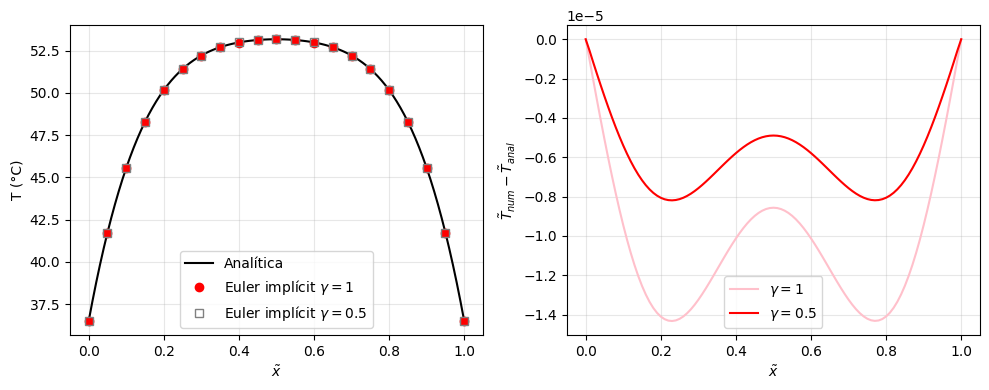

In [39]:
# REPRESENTACIÓ GRÀFICA EULER IMPLÍCIT

x, T1  = euler_implicit(N, 1.0, t_a, Tc_norm)
x, T05 = euler_implicit(N, 0.5, t_a, Tc_norm)
Ta = T_analitica(x, t_a, Tc_norm)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 4))   # 1 fila, 2 gràfics

# Gràfic temperatura
ax[0].plot(x, T_0*Ta, 'k-', label='Analítica')
ax[0].plot(x[::5], T_0*T1[::5], 'o', color='red', label=r'Euler implícit $\gamma=1$')
ax[0].plot(x[::5], T_0*T05[::5], 's', color='grey', mfc='none', label=r'Euler implícit $\gamma=0.5$')
ax[0].set_xlabel(r'$\tilde{x}$')
ax[0].set_ylabel('T (°C)')
ax[0].legend()
ax[0].grid(alpha=0.3)

# Gràfic error
ax[1].plot(x, T1 - Ta, color='pink', label=r'$\gamma=1$')
ax[1].plot(x, T05 - Ta, color='red', label=r'$\gamma=0.5$')
ax[1].set_xlabel(r'$\tilde{x}$')
ax[1].set_ylabel(r'$\tilde{T}_{num}-\tilde{T}_{anal}$')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Mètode Crank-Nicolson

In [40]:
'''Abans d'aplicar Crank-Nicolson fem servir el mètode Gauss amb pivot absolut
   explicat a classe per a simplificar la matriu i poder-la resoldre de forma
   més senzilla, ràpida i endreçada'''

#MÈTODE DE GAUSS

def gauss_pivotatge(matriu, indep):

    # Còpia de les matrius originals
    A = matriu.copy()
    b = indep.copy()

    # Orde de les columnes
    ordre_columnes = np.arange(len(b))

    for i in range(len(A) - 1):

        # Busquem l'element més gran de la matriu
        subA = A[i:, i:]
        idx_flat = np.argmax(np.abs(subA))
        i_sub, j_sub = np.unravel_index(idx_flat, subA.shape)

        max_idx = i + i_sub
        max_jdx = i + j_sub

        # Intercanviem files i columnes
        A[[i, max_idx]] = A[[max_idx, i]]
        A[:, [i, max_jdx]] = A[:, [max_jdx, i]]
        b[[i, max_idx]] = b[[max_idx, i]]
        ordre_columnes[[i, max_jdx]] = ordre_columnes[[max_jdx, i]]

        # Eliminació de Gauss
        mult = A[i+1:, i] / A[i, i]
        b[i+1:] -= mult * b[i]
        A[i+1:, i:] -= mult[:, np.newaxis] * A[i, i:]

    # Substitució regresiva
    x_desord = np.zeros(len(b))

    for i in range(len(b) - 1, -1, -1):
        suma = np.dot(A[i, i+1:], x_desord[i+1:])
        x_desord[i] = (b[i] - suma) / A[i, i]

    # Recuperem l'ordre original de les incògnites
    x_ordenat = np.zeros(x_desord.shape)
    x_ordenat[ordre_columnes] = x_desord

    return x_ordenat

In [41]:
# MÈTODE DE CRANCK-NICOLSON

# Definim la funció Crank-Nicolson

def crank_nicolson(dx, dt):

    iteracions = int(t_a / dt) + 1
    beta = dt / (2 * dx**2)

    # Matriu de temperatures
    T = np.zeros((iteracions, N))

    # Construïm la matriu tridiagonal A
    A = np.zeros((N-2, N-2))

    for i in range(N-2):
        A[i, i] = 1 + 2*beta

        if i != 0:
            A[i-1, i] = -beta

        if i != N-3:
            A[i+1, i] = -beta

    # Iteracions temporals (formula teòrica: Algorisme de Crank-Nicolson)
    for i in range(1, iteracions):

        B = (
            beta * T[i-1, :-2]
            + (1 - 2*beta) * T[i-1, 1:-1]
            + beta * T[i-1, 2:]
            + dt
        )

        # Resolem el sistema amb Gauss i pivotatge total
        T[i, 1:-1] = gauss_pivotatge(A, B)

    # Afegim la temperatura inicial normalitzada
    return T + normalitza_temperatura(T_c)


#Executem el mètode i guardem els resultats

resultats = {}

# Discretització espacial
dx = 1 / (N - 1)

for factor_dt in factors_dt:

    # Discretització temporal
    dt = factor_dt * dx**2

    # Executem Crank-Nicolson
    T = crank_nicolson(dx, dt)

    # Desnormalitzem la temperatura
    T = desnormalitza_temperatura(T)

    # Guardem els resultats
    resultats[factor_dt] = T

    print(f"Δx = {dx:.4f}")
    print(f"Δt = {dt:.6f}")
    print(f"Temperatura màxima = {np.max(T[-1]):.4f} °C")
    print(f"Temperatura als extrems = {T[-1, 0]:.4f} °C")

Δx = 0.0100
Δt = 0.000050
Temperatura màxima = 53.1664 °C
Temperatura als extrems = 36.5000 °C
Δx = 0.0100
Δt = 0.000100
Temperatura màxima = 53.1664 °C
Temperatura als extrems = 36.5000 °C


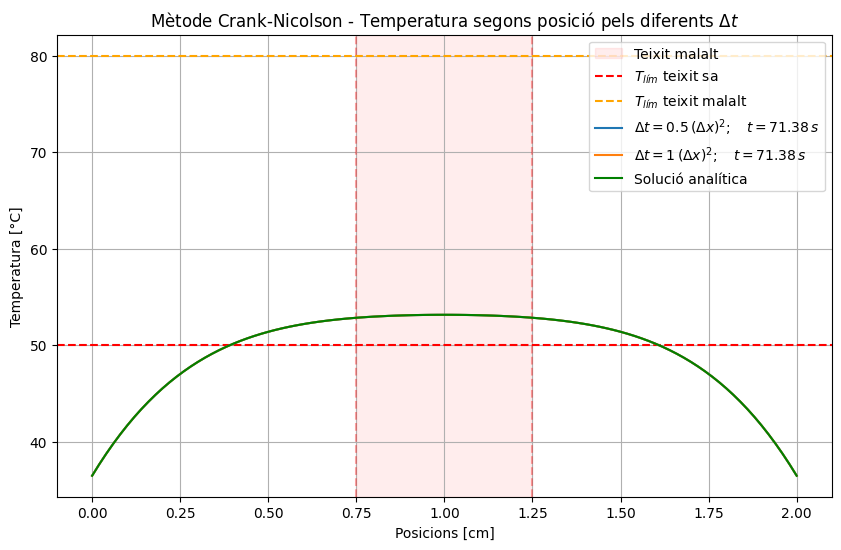

Factor temporal = 0.5
Error relatiu màxim = 0.000027

Factor temporal = 1
Error relatiu màxim = 0.000027



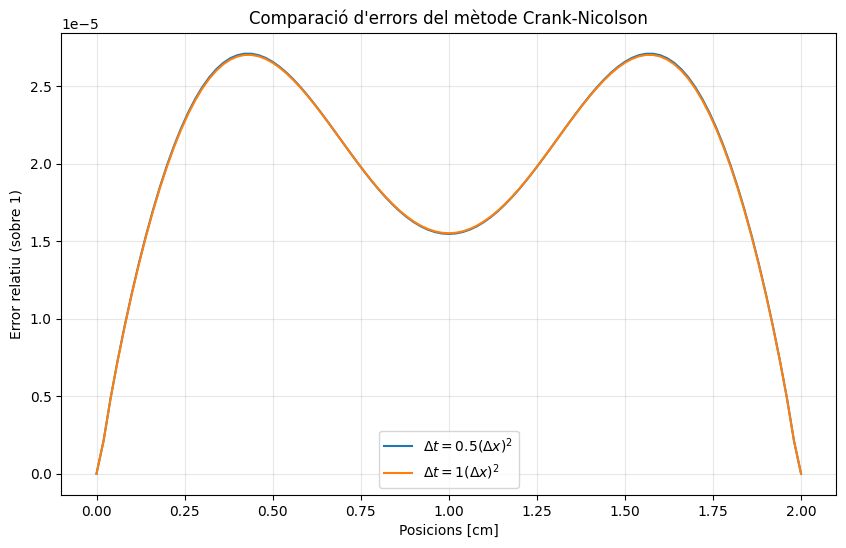

In [42]:
#REPRESENTACIÓ GRÀFICA CRANK-NICOLSON

#Temperatura segons posició

# Posicions espacials en centímetres
x = np.linspace(0, d, N) * 100

plt.figure(figsize=(10, 6))

# Límits entre teixit sa i malalt
x_esq = (d - d_malalt) / 2 * 100
x_dret = (d + d_malalt) / 2 * 100

# Regió del teixit malalt
plt.axvspan(x_esq, x_dret, color="red", alpha=0.07, label="Teixit malalt")

#Línies límits entre teixit sa i malalt
plt.axvline(x_esq, color="red", linestyle="--", alpha=0.35)
plt.axvline(x_dret, color="red", linestyle="--", alpha=0.35)

# Temperatures límit
plt.axhline(50, color="red", linestyle="--", label=r"$T_{lím}$ teixit sa")
plt.axhline(80, color="orange", linestyle="--", label=r"$T_{lím}$ teixit malalt")

# Resultats de Crank-Nicolson
for factor_dt in factors_dt:

    T = resultats[factor_dt]

    dt = factor_dt * dx**2
    temps = (len(T) - 1) * dt * t_0

    plt.plot(x, T[-1, :], label=rf"$\Delta t={factor_dt}\,(\Delta x)^2;\quad t={temps:.2f}\,s$")

# Solució analítica
x_adim = np.linspace(0, 1, N)
plt.plot(x, T_analitica(x_adim, t_a, Tc_norm)*T_0, color="green", label="Solució analítica")


plt.xlabel("Posicions [cm]")
plt.ylabel("Temperatura [°C]")
plt.title(r"Mètode Crank-Nicolson - Temperatura segons posició pels diferents $\Delta t$")
plt.legend()
plt.grid()
plt.show()

# ERROR CRANK-NICOLSON

errors = {}

# Posicions adimensionals
x_adim = np.linspace(0, 1, N)

for factor_dt in factors_dt:

    # Resultat numèric
    T_num = resultats[factor_dt][-1, :]

    # Temps final adimensional
    dt = factor_dt * dx**2
    t = (len(resultats[factor_dt]) - 1) * dt

    # Solució analítica
    T_an = T_analitica(x_adim, t, Tc_norm)*T_0

    # Error relatiu
    error = np.abs(T_num - T_an) / np.abs(T_an)

    errors[factor_dt] = error

    print(f"Factor temporal = {factor_dt}")
    print(f"Error relatiu màxim = {np.max(error):.6f}")
    print()

# COMPARACIÓ D'ERRORS DE CRANK-NICOLSON

# Posicions espacials en centímetres
x = np.linspace(0, d, N) * 100

plt.figure(figsize=(10, 6))

for factor_dt in factors_dt:

    error = errors[factor_dt]

    plt.plot(
        x, error,
        label=rf"$\Delta t={factor_dt}"rf"(\Delta x)^2$"
    )

plt.xlabel("Posicions [cm]")
plt.ylabel("Error relatiu (sobre 1)")
plt.title("Comparació d'errors del mètode Crank-Nicolson")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Ressolució del problema

Temps mínim per assolir 50 °C: 58.250 s
Temperatura mínima del teixit malalt: 50.026 °C
Temperatura màxima del teixit malalt: 50.183 °C
Temperatura màxima del teixit sa: 49.993 °C
El teixit sa supera els 50 °C a t = 58.393 s
EL TEMPS ÒPTIM ÉS: 58.250 s


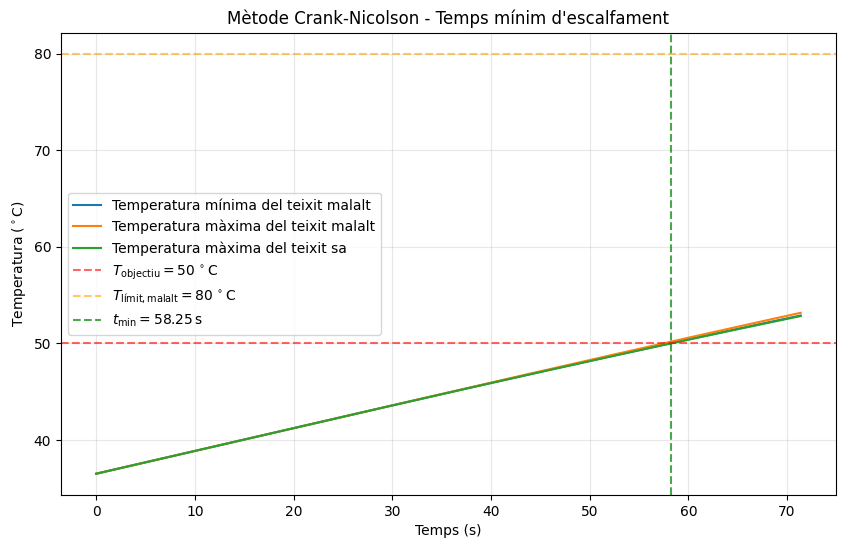

In [43]:
''' Considerem que el temps òptim és aquell que, minimitza el teixit sa cremat, és a dir,
    s'aplica el temps mínim possible  el voltatge, però que aconsegueix cremar tot el teixit en mal estat.
    Mentrestant, es revisa que durant tot el procés no es sobrepassi en cap moment la temperatura límit de 80ºC que comprometria la salut del pacient. '''


# CÀLCUL DEL TEMPS ÒPTIM - MÈTODE CRANK-NICOLSON

# Seleccionem la discretització temporal
factor_dt = factors_dt[0]
dx = 1 / (N - 1)
dt = factor_dt * dx**2

# Executem el mètode Crank-Nicolson
T = crank_nicolson(dx, dt)
T = desnormalitza_temperatura(T)

# Vector temporal en segons
temps = np.arange(len(T)) * dt * t_0

# Posicions espacials
x = np.linspace(0, d, N)

# Límits del teixit malalt
x_esq = (d - d_malalt) / 2
x_dret = (d + d_malalt) / 2

# Identifiquem les regions de teixit sa i malalt
teixit_malalt = (x >= x_esq) & (x <= x_dret)
teixit_sa = ~teixit_malalt

# Temperatures mínima i màxima del teixit malalt
T_min_malalt = np.min(T[:, teixit_malalt], axis=1)
T_max_malalt = np.max(T[:, teixit_malalt], axis=1)

# Temperatura màxima del teixit sa
T_max_sa = np.max(T[:, teixit_sa], axis=1)

# Temperatures límit
T_objectiu = 50
T_limit_malalt = 80
T_limit_sa = 50

# Primer instant en què tot el teixit malalt arriba a 50 °C
index = np.where(T_min_malalt >= T_objectiu)[0]

# Primer instant en què se superen els límits
index_80 = np.where(T_max_malalt > T_limit_malalt)[0]
index_sa = np.where(T_max_sa > T_limit_sa)[0]

if len(index) > 0:

    i_optim = index[0]
    t_optim = temps[i_optim]

    print(f"Temps mínim per assolir 50 °C: {t_optim:.3f} s")
    print(f"Temperatura mínima del teixit malalt: {T_min_malalt[i_optim]:.3f} °C")
    print(f"Temperatura màxima del teixit malalt: {T_max_malalt[i_optim]:.3f} °C")
    print(f"Temperatura màxima del teixit sa: {T_max_sa[i_optim]:.3f} °C")

    if T_max_malalt[i_optim] > T_limit_malalt:
        print("AVÍS: Se supera el límit de 80 °C del teixit malalt!")

    if T_max_sa[i_optim] > T_limit_sa:
        print("AVÍS: Se supera el límit de 50 °C del teixit sa!")

else:
    print("No s'assoleixen els 50 °C en tot el teixit malalt durant la simulació.")

if len(index_80) > 0:
    print(f"El teixit malalt supera els 80 °C a t = {temps[index_80[0]]:.3f} s")

if len(index_sa) > 0:
    print(f"El teixit sa supera els 50 °C a t = {temps[index_sa[0]]:.3f} s")

print(f"EL TEMPS ÒPTIM ÉS: {t_optim:.3f} s")

# REPRESENTACIÓ GRÀFICA

plt.figure(figsize=(10, 6))

plt.plot(temps, T_min_malalt,
         label="Temperatura mínima del teixit malalt")

plt.plot(temps, T_max_malalt,
         label="Temperatura màxima del teixit malalt")

plt.plot(temps, T_max_sa,
         label="Temperatura màxima del teixit sa")

# Temperatures límit
plt.axhline(T_objectiu, color="red", linestyle="--", alpha=0.6,
            label=r"$T_{\mathrm{objectiu}}=50\,^\circ\mathrm{C}$")

plt.axhline(T_limit_malalt, color="orange", linestyle="--", alpha=0.6,
            label=r"$T_{\mathrm{límit,malalt}}=80\,^\circ\mathrm{C}$")

# Temps mínim
if len(index) > 0:
    plt.axvline(t_optim, color="green", linestyle="--", alpha=0.7,
                label=rf"$t_{{\min}}={t_optim:.2f}\,\mathrm{{s}}$")

plt.xlabel("Temps (s)")
plt.ylabel(r"Temperatura ($^\circ$C)")
plt.title("Mètode Crank-Nicolson - Temps mínim d'escalfament")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

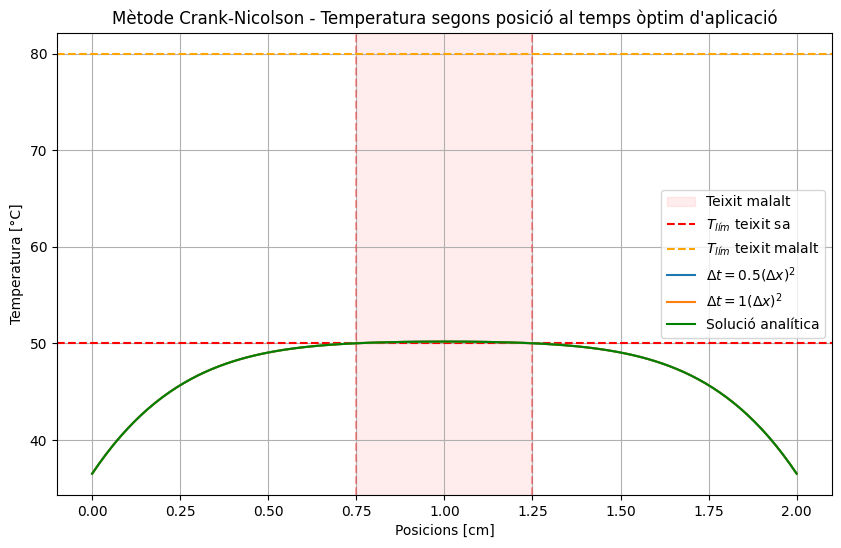

In [44]:
#REPRESENTACIÓ GRÀFICA SOLUCIÓ PROBLEMA
#Temperatura segons posició al temps òptim

# Posicions espacials en centímetres
x = np.linspace(0, d, N) * 100

plt.figure(figsize=(10, 6))

# Límits entre teixit sa i malalt
x_esq = (d - d_malalt) / 2 * 100
x_dret = (d + d_malalt) / 2 * 100

# Regió del teixit malalt
plt.axvspan(x_esq, x_dret, color="red", alpha=0.07, label="Teixit malalt")

#Línies límits entre teixit sa i malalt
plt.axvline(x_esq, color="red", linestyle="--", alpha=0.35)
plt.axvline(x_dret, color="red", linestyle="--", alpha=0.35)

# Temperatures límit
plt.axhline(50, color="red", linestyle="--", label=r"$T_{lím}$ teixit sa")
plt.axhline(80, color="orange", linestyle="--", label=r"$T_{lím}$ teixit malalt")

# Resultats de Crank-Nicolson pel temps òptim
for factor_dt in factors_dt:

    T = resultats[factor_dt]

    dt = factor_dt * dx**2
    temps = (len(T) - 1) * dt * t_0

    # Índex temporal corresponent al temps òptim

    i = min(round(t_optim / (dt * t_0)), len(T) - 1)

    plt.plot(x, T[i, :], label=rf"$\Delta t={factor_dt}(\Delta x)^2$")


# Solució analítica al temps òptim
x_adim = np.linspace(0, 1, N)
t_optim_adim = t_optim / t_0

plt.plot(x, T_analitica(x_adim, t_optim_adim, Tc_norm)*T_0, color="green", label="Solució analítica")


plt.xlabel("Posicions [cm]")
plt.ylabel("Temperatura [°C]")
plt.title("Mètode Crank-Nicolson - Temperatura segons posició al temps òptim d'aplicació")
plt.legend()
plt.grid()
plt.show()